# Using coxdev

`coxdev` computes the deviance of the Cox proportional hazards model, its
gradient and the diagonal of its Hessian with respect to the linear
predictor, the information as a matrix-free operator, the score residuals,
the baseline hazard, and draws of the score. This notebook fits a model by
Newton's method, computes robust standard errors and survival curves, and
shows what keeping the sorted data in a `CoxDeviance` object saves. Sampling
the score has its own notebook, `sampling.md`. The R package has the same
two vignettes.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from coxdev import CoxDeviance
from glmnet.cox import CoxFamily, CoxNetIRLS
from glmnet.glmnet import GLMNetControl

## A survival response

Survival times on a coarse grid, so that there are many ties, with delayed
entry and censoring.

In [2]:
rng = np.random.default_rng(1)
n, p = 500, 3
X = rng.standard_normal((n, p))
beta = np.array([0.5, -0.5, 0.25])
T = rng.exponential(1 / np.exp(X @ beta))
C = rng.exponential(2, n)
stop = np.ceil(np.minimum(T, C) * 4) / 4
status = (T <= C).astype(int)
start = np.floor(rng.uniform(0, 0.5, n) * stop * 8) / 8

cox = CoxDeviance(event=stop, status=status, start=start, tie_breaking='efron')

## Deviance, gradient and information

Calling the object returns the deviance and its derivatives with respect to
the linear predictor `eta`. `information()` returns the information (half the
Hessian of the deviance) as an `n` by `n` `LinearOperator`. It is never
formed: a product with it costs about as much as a gradient. For a design
`X`, `X.T @ (I @ X)` is the information of the coefficients, so Newton's
method takes a few lines.

In [3]:
b = np.zeros(p)
for iteration in range(1, 11):
    eta = X @ b
    res = cox(eta)
    score = X.T @ (-res.gradient / 2)
    info = X.T @ (cox.information(eta) @ X)
    step = np.linalg.solve(info, score)
    b = b + step
    if np.max(np.abs(step)) < 1e-10:
        break
iteration, b

(5, array([ 0.450718  , -0.40934622,  0.24829713]))

These are the estimates of `CoxNetIRLS` from `glmstar`, the Python glmnet,
fit with no penalty:

In [4]:
y = pd.DataFrame({'start': start, 'stop': stop, 'status': status})
coxnet = CoxNetIRLS(family=CoxFamily(tie_breaking='efron', event_id='stop',
                                     status_id='status', start_id='start'),
                    lambda_values=np.array([0.]),
                    control=GLMNetControl(thresh=1e-14, epsnr=1e-12))
with np.errstate(invalid='ignore'):  # glmstar 0.1.3 divides 0 by 0 at lambda = 0
    fit = coxnet.fit(X, y)
pd.DataFrame({'coxdev': b, 'CoxNetIRLS': fit.coefs_[0]}, index=['x1', 'x2', 'x3'])

,coxdev,CoxNetIRLS
x1,0.450718,0.450718
x2,-0.409346,-0.409346
x3,0.248297,0.248297


At the estimate the score is zero, and the inverse of the information gives
the standard errors. (The tests check these against R's `coxph`.)

In [5]:
eta_hat = X @ b
info_hat = X.T @ (cox.information(eta_hat) @ X)
pd.DataFrame({'coef': b,
              'se': np.sqrt(np.diag(np.linalg.inv(info_hat))),
              'score': X.T @ (-cox(eta_hat).gradient / 2)},
             index=['x1', 'x2', 'x3'])

,coef,se,score
x1,0.450718,0.061453,6.126192e-14
x2,-0.409346,0.061937,-6.346278e-14
x3,0.248297,0.057601,-1.754083e-15


## Robust standard errors and the baseline hazard

The score residuals of the design give the robust (sandwich) variance,
`inv(I) @ U.T @ U @ inv(I)`:

In [6]:
U = cox.score_residuals(eta_hat, X)
robust = np.linalg.solve(info_hat, np.linalg.solve(info_hat, U.T @ U).T)
pd.DataFrame({'se': np.sqrt(np.diag(np.linalg.inv(info_hat))),
              'robust se': np.sqrt(np.diag(robust))},
             index=['x1', 'x2', 'x3'])

,se,robust se
x1,0.061453,0.052448
x2,0.061937,0.053173
x3,0.057601,0.048261


`baseline_hazard()` gives Efron's estimate of the cumulative baseline hazard
(Breslow's with `tie_breaking='breslow'`), R's
`basehaz(fit, centered = FALSE)`. The survival curve of a subject with
covariates `x0` is `exp(-cumulative_hazard * exp(x0 @ b))`:

In [7]:
H = cox.baseline_hazard(eta_hat)
pd.DataFrame({'time': H.time, 'hazard': H.hazard,
              'cumulative_hazard': H.cumulative_hazard}).head(6)

,time,hazard,cumulative_hazard
0,0.25,0.355443,0.355443
1,0.50,0.228773,0.584216
2,0.75,0.279238,0.863454
3,1.00,0.155279,1.018734
4,1.25,0.270426,1.289160
5,1.50,0.164843,1.454003


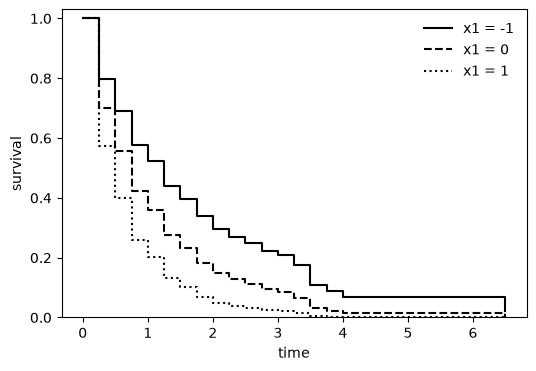

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
for x1, ls in zip([-1, 0, 1], ['-', '--', ':']):
    surv = np.exp(-H.cumulative_hazard * np.exp(b[0] * x1))
    ax.step(np.r_[0, H.time], np.r_[1, surv], where='post', ls=ls, color='k',
            label=f'x1 = {x1}')
ax.set_xlabel('time')
ax.set_ylabel('survival')
ax.set_ylim(0, 1.03)
ax.legend(frameon=False);

## What keeping state saves

Creating a `CoxDeviance` sorts the data, once. Each call after that is
linear in `n`, and repeating a call with the same linear predictor and
weights returns the cached result. A stateless function has to sort on every
call. That cost is paid at every step of an optimizer, and at every
product with the information.

We time 50 evaluations of the deviance and gradient at 100,000 observations,
each at a different linear predictor.

In [9]:
rng = np.random.default_rng(2)
N = 100_000
XN = rng.standard_normal((N, p))
etaN = XN @ beta
stopN = np.ceil(rng.exponential(1 / np.exp(etaN)) * 20) / 20
statusN = rng.binomial(1, 0.7, N)
startN = np.floor(rng.uniform(0, 0.5, N) * stopN * 40) / 40
etas = [etaN + rng.normal(0, 0.1, N) for _ in range(50)]

def per_call(f):
    t = time.perf_counter()
    for e in etas:
        f(e)
    return f'{1000 * (time.perf_counter() - t) / len(etas):.1f} ms'

t = time.perf_counter()
coxN = CoxDeviance(event=stopN, status=statusN, start=startN)
setup = 1000 * (time.perf_counter() - t)
I = coxN.information(etas[0])
timings = {
    'one object, reused': per_call(lambda e: coxN(e)),
    'a new object for each call': per_call(
        lambda e: CoxDeviance(event=stopN, status=statusN, start=startN)(e)),
    'one object, same eta again (cached)': per_call(lambda e: coxN(etas[0])),
    'one information product': per_call(lambda e: I @ XN[:, 0]),
}
print(f'Creating the object (the sort) took {setup:.0f} ms.')
pd.DataFrame({'time per call': timings})

Creating the object (the sort) took 12 ms.


,time per call
"one object, reused",4.8 ms
a new object for each call,15.3 ms
"one object, same eta again (cached)",2.9 ms
one information product,0.7 ms


The times depend on the machine, but the pattern is stable. Reusing the
object avoids the sort, which costs several times as much as an evaluation.
The information operator is what makes the Hessian usable at this size: as a
dense matrix it would take

In [10]:
f'{8 * N**2 / 2**30:.1f} GB'

'74.5 GB'